In [1]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import torch

# Vinculação com a GPU deste PC
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo selecionado: {device}")
if torch.cuda.is_available():
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")

# Importa as bibliotecas desenvolvidas para o projeto
import quantum_tomography as qt
import entropyreg_torch as er

Dispositivo selecionado: cuda
GPU detectada: NVIDIA RTX A4500


In [2]:
# Funções criadas pela IA que ainda preciso entender o pq foram feitas (versão PyTorch / GPU)
def rho_a_partir_de_u(u, H, Q_list, epsilon):
    u_t, H_t, Q_t = er._prepare_inputs(u, H, Q_list, device=device)
    if Q_t.ndim == 3:
        operador = torch.tensordot(u_t.to(torch.complex128), Q_t, dims=([0], [0])) - H_t
    else:
        operador = sum(u_i * Q_i for u_i, Q_i in zip(u_t, Q_t)) - H_t
    return torch.linalg.matrix_exp(operador / epsilon)


def normalizar_rho(rho):
    rho_t = er.to_tensor(rho, dtype=torch.complex128, device=device)
    tr = torch.real(torch.trace(rho_t))
    if not torch.isfinite(tr) or tr <= 0:
        raise ValueError("A exponencial não produziu um traço positivo e finito.")
    return rho_t / tr


def entropia_von_neumann(rho):
    rho_t = er.to_tensor(rho, dtype=torch.complex128, device=device)
    rho_h = (rho_t + rho_t.mH) / 2
    autovalores = torch.linalg.eigvalsh(rho_h)
    autovalores = torch.clamp(autovalores, min=0.0)
    positivos = autovalores[autovalores > 1e-14]
    return float(-torch.sum(positivos * torch.log(positivos)).item())


def estado_gibbs(H, beta):
    """Estado térmico exp(-beta H)/Z. Função auxiliar deste notebook."""
    H_t = er.to_tensor(H, dtype=torch.complex128, device=device)
    return normalizar_rho(torch.linalg.matrix_exp(-beta * H_t))


def montar_observaveis_pauli(n_qubits):
    nomes = ["I" * n_qubits] + qt.pauli_basis_strings(n_qubits)
    matrizes = [qt.pauli_string_to_matrix(nome) for nome in nomes]
    # Empilhado como tensor PyTorch complex128 na GPU
    matrizes_gpu = torch.tensor(np.array(matrizes), dtype=torch.complex128, device=device)
    return nomes, matrizes_gpu


def fidelidade_gpu(rho_a, rho_b):
    """Fidelidade Uhlmann-Jozsa calculada diretamente na GPU com PyTorch."""
    def sqrt_psd(mat):
        mat_h = (mat + mat.mH) / 2.0
        eigvals, eigvecs = torch.linalg.eigh(mat_h)
        eigvals = torch.clamp(eigvals, min=0.0)
        return (eigvecs * torch.sqrt(eigvals).unsqueeze(-2)) @ eigvecs.mH

    rho_a = er.to_tensor(rho_a, dtype=torch.complex128, device=device)
    rho_b = er.to_tensor(rho_b, dtype=torch.complex128, device=device)
    sa = sqrt_psd(rho_a)
    m = sa @ rho_b @ sa
    sm = sqrt_psd(m)
    tr = torch.real(torch.trace(sm))
    return float(torch.clamp(tr ** 2, min=0.0, max=1.0).item())


def rodar_estocastico_com_historico(H, Q_list, q, epsilon, k, lr,
                                    max_iters=5000, tol=1e-6, seed=0,
                                    check_every=10):
    """
    Atualiza k coordenadas sorteadas. A cada check_every passos, calcula
    a norma do gradiente completo para avaliar/parar o método.
    """
    u = torch.zeros(len(q), dtype=torch.float64, device=device)
    m = len(q)
    g0 = er.dual_gradient(u, H, Q_list, q, epsilon, device=device)
    historico = [[0, torch.linalg.norm(g0).item()]]
    inicio = time.perf_counter()

    for t in range(1, max_iters + 1):
        grad_parcial, _ = er.stochastic_gradient(
            u, H, Q_list, q, epsilon, rng=seed, k=k, device=device
        )
        if not torch.all(torch.isfinite(grad_parcial)):
            break
        u -= lr * grad_parcial

        if t % check_every == 0:
            grad_completo, _ = er.stochastic_gradient(
                u, H, Q_list, q, epsilon, rng=seed, k=m, device=device
            )
            norma = torch.linalg.norm(grad_completo).item()
            historico.append([t, norma])
            if np.isfinite(norma) and norma < tol:
                break

    tempo = time.perf_counter() - inicio
    return u, t, np.asarray(historico), tempo

Sanity check, verificação de que ambos os métodos funcionam para um mesmo problema com os mesmos parâmetros.

In [3]:
Q = torch.tensor(np.array([np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]), dtype=torch.complex128, device=device)
q = torch.tensor([1, 0.7, 0.4], dtype=torch.float64, device=device)
H = 0
epsilon = 1

# Teste com Gradient Ascent
pistar_data = er.reconstruct_pi(H, Q, q, epsilon, lr=1, max_iters=10000, tol=1e-6)
pistar = pistar_data[0]

print("Com o método de Gradient Ascent:")
print("Valores das médias com os observáveis I, Sigma_x, Sigma_y:" )
print(torch.trace(pistar).item(), torch.trace(pistar @ Q[1]).item(), torch.trace(pistar @ Q[2]).item())
print("Número de iterações: ", pistar_data[2])
print("Matriz reconstruída pi*:")
print(pistar)

# Teste com Stochastic Gradient Ascent
stocpistar_data = er.reconstruct_spi(H, Q, q, epsilon, max_iters=5000, lr=1, tol=1e-6, k=2, count_it=1)
stocpistar, stoc_u_opt, stoc_n_it, stoc_pi_grad  = stocpistar_data
stoc_grad_data = np.array(stoc_pi_grad)

print("Com o método de Stochastic Gradient Ascent:")
print("Valores das médias com os observáveis I, Sigma_x, Sigma_y:" )
print(torch.trace(stocpistar).item(), torch.trace(stocpistar @ Q[1]).item(), torch.trace(stocpistar @ Q[2]).item())
print("iterações:", stoc_n_it)
print("Matriz reconstruída pi*:")
print(stocpistar)

Com o método de Gradient Ascent:
Valores das médias com os observáveis I, Sigma_x, Sigma_y:
(1.0000008181897564+5.609472531925166e-19j) (0.700000247261408+2.7755575615628914e-17j) (0.40000014129223316+0j)
Número de iterações:  56
Matriz reconstruída pi*:
tensor([[0.5000-2.2029e-19j, 0.3500-2.0000e-01j],
        [0.3500+2.0000e-01j, 0.5000+7.8124e-19j]], device='cuda:0',
       dtype=torch.complex128)
Com o método de Stochastic Gradient Ascent:
Valores das médias com os observáveis I, Sigma_x, Sigma_y:
(1.0000000077339426+3.1594129535171405e-19j) (0.6999999964841418+0j) (0.3999999915390142+0j)
iterações: 100
Matriz reconstruída pi*:
tensor([[0.5000+1.8802e-18j, 0.3500-2.0000e-01j],
        [0.3500+2.0000e-01j, 0.5000-1.5642e-18j]], device='cuda:0',
       dtype=torch.complex128)


Definimos agora um estado alvo de 3 qubits para realizar a comparação entre os métodos, e então, escolhermos um para prosseguir nossa abordagem.

In [4]:
n_qubits = 3
estado_alvo = qt.random_mixture_of_pures(dim=2**n_qubits, rank=4, seed=17)
estado_alvo_rho = torch.tensor(estado_alvo.rho, dtype=torch.complex128, device=device)

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
q = torch.tensor(qt.measure_observables(estado_alvo, nomes_obs), dtype=torch.float64, device=device)
H = torch.zeros((2**n_qubits, 2**n_qubits), dtype=torch.complex128, device=device)
epsilon = 1.0

print(estado_alvo)
print("Número de observáveis:", len(Q))
print("Traço do estado-alvo:", torch.trace(estado_alvo_rho).real.item())
print("Autovalores do estado-alvo:", torch.linalg.eigvalsh(estado_alvo_rho).cpu().numpy())

<QuantState (3 qubits, Misto (posto 4), pureza=0.336)>
Número de observáveis: 64
Traço do estado-alvo: 1.0
Autovalores do estado-alvo: [-8.40214507e-17 -4.85882338e-17  8.29505466e-19  3.83458424e-17
  9.90608868e-02  1.26475398e-01  3.13921218e-01  4.60542498e-01]


In [5]:
lr_comparacao = 0.5
tol = 1e-6
check_every = 10
max_iters = 100000

# Gradient Descent completo
t0 = time.perf_counter()
gd_data = er.gradient_descent(
    H, Q, q, epsilon, max_iters=max_iters, lr=lr_comparacao, tol=tol
)
tempo_gd = time.perf_counter() - t0
u_gd, it_gd, us_gd, grad_gd = gd_data

# Método estocástico com k coordenadas por iteração
t0 = time.perf_counter()
u_st, it_st, hist_st = er.sgd(
    H, Q, q, epsilon, k=len(Q)//2, lr=lr_comparacao,
    n_iter=max_iters, tol=tol, seed=0,
    check_every=check_every, count_it=check_every
)
tempo_st = time.perf_counter() - t0

rho_gd = normalizar_rho(rho_a_partir_de_u(u_gd, H, Q, epsilon))
rho_st = normalizar_rho(rho_a_partir_de_u(u_st, H, Q, epsilon))

print("Gradient Descent")
print("iterações:", it_gd, "| tempo (s):", round(tempo_gd, 4))
print("norma final do gradiente:", torch.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon)).item())
print("fidelidade:", fidelidade_gpu(rho_gd, estado_alvo_rho))

print("\nMétodo estocástico")
print("iterações:", it_st, "| tempo (s):", round(tempo_st, 4))
print("norma final do gradiente:", torch.linalg.norm(er.dual_gradient(u_st, H, Q, q, epsilon)).item())
print("fidelidade:", fidelidade_gpu(rho_st, estado_alvo_rho))

Gradient Descent
iterações: 100000 | tempo (s): 53.7183
norma final do gradiente: 1.4139716064858802e-05
fidelidade: 0.9999900140260343

Método estocástico
iterações: 100000 | tempo (s): 79.5469
norma final do gradiente: 3.216261950383067e-05
fidelidade: 0.9999800074872874


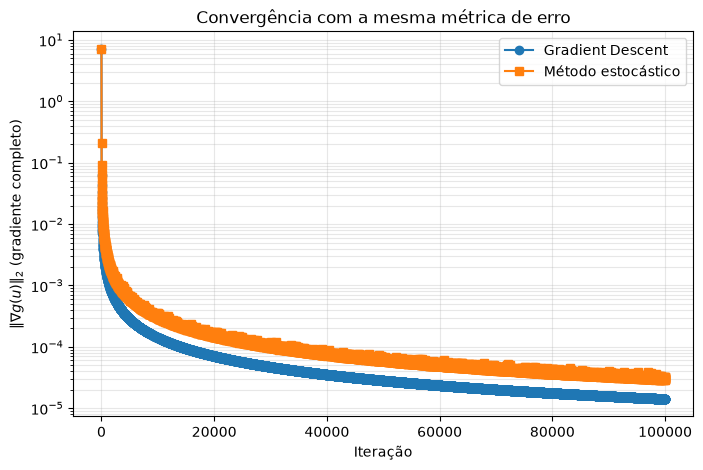

In [6]:
# O GD registra todos os passos; selecionamos os mesmos instantes usados no SGD.
hist_gd = np.asarray(grad_gd)
hist_gd = hist_gd[hist_gd[:, 0] % check_every == 0]
grad_gd_final = torch.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon)).item()
if hist_gd[-1, 0] != it_gd:
    hist_gd = np.vstack([hist_gd, [it_gd, grad_gd_final]])

hist_st = np.asarray(hist_st)
grad_inicial = torch.linalg.norm(
    er.dual_gradient(torch.zeros(len(q), dtype=torch.float64, device=device), H, Q, q, epsilon)
).item()
hist_st = np.vstack([[0, grad_inicial], hist_st])

plt.figure(figsize=(8, 5))
plt.semilogy(hist_gd[:, 0], hist_gd[:, 1], "o-", label="Gradient Descent")
plt.semilogy(hist_st[:, 0], hist_st[:, 1], "s-", label="Método estocástico")
plt.xlabel("Iteração")
plt.ylabel(r"$\|\nabla g(u)\|_2$ (gradiente completo)")
plt.title("Convergência com a mesma métrica de erro")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

Selecionamos então o stochastic method pois ele aparenta funcionar melhor na questão de memória para problemas com dimensionalidade maior. Desse modo, agora vamos definir um estado arbitrário alvo, e verificar a convergência do método variando tanto o learning rate como o epsilon(correspondente à temperatura).

In [7]:
n_qubits = 3
estado_alvo = qt.random_mixture_of_pures(dim=2**n_qubits, seed=35)
estado_alvo_rho = torch.tensor(estado_alvo.rho, dtype=torch.complex128, device=device)

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
q = torch.tensor(qt.measure_observables(estado_alvo, nomes_obs), dtype=torch.float64, device=device)
H = torch.zeros((2**n_qubits, 2**n_qubits), dtype=torch.complex128, device=device)

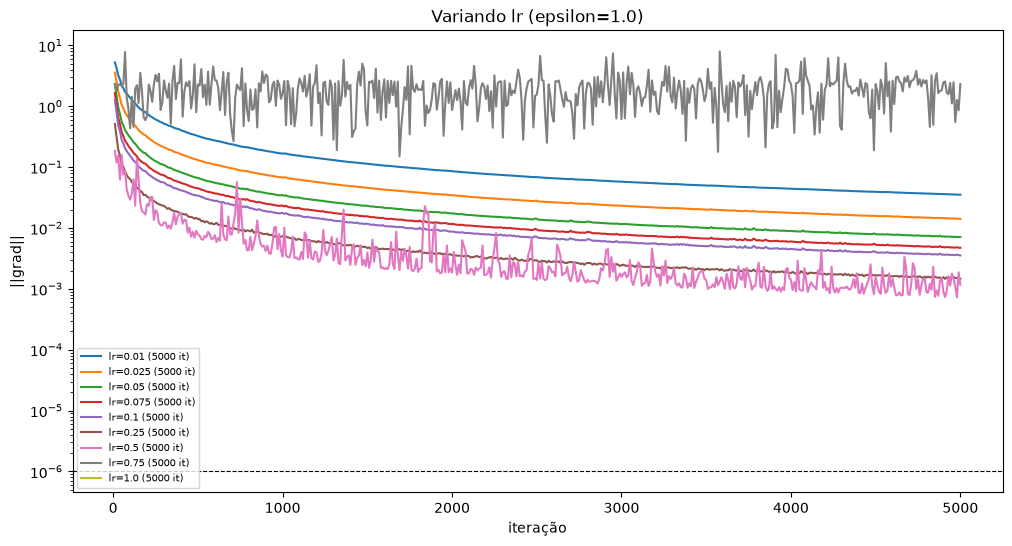

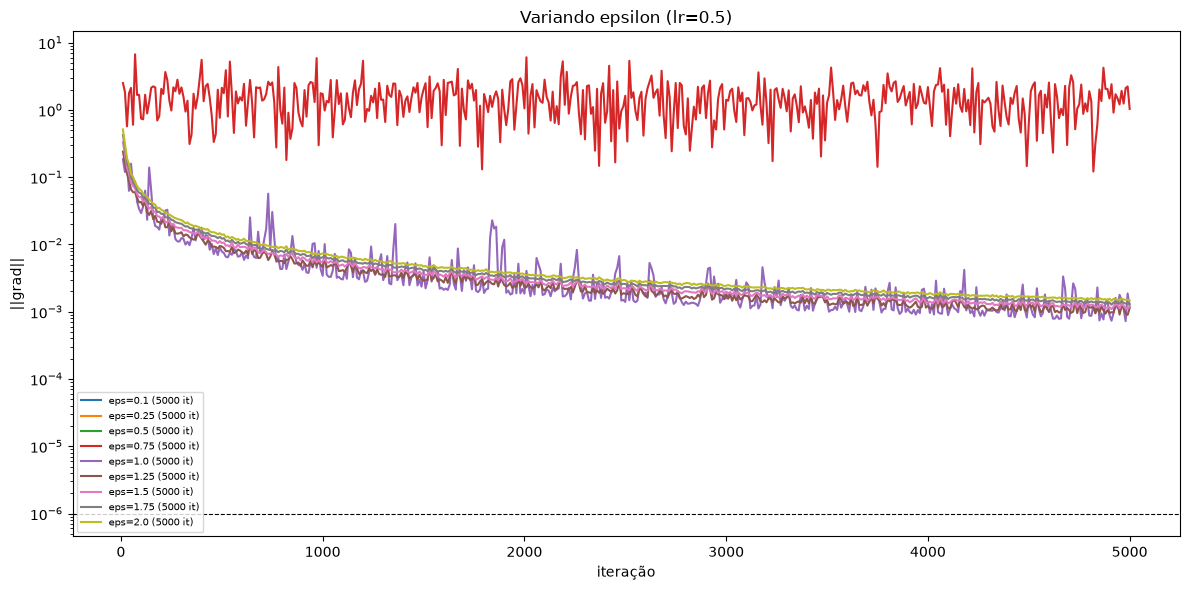

In [8]:
tol_fix = 1e-6
check_every_fix = 50
max_iters_fix = 5000

seeds = range(5)
epsilon_values = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_values = [0.01,0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75, 1.0]

lr_fix = 0.5
epsilon_fix = 1.0

k = len(Q) // 2


def rodar(lr, epsilon):
    u, n_it, hist = er.sgd(H, Q, q, epsilon, k=k, lr=lr, n_iter=max_iters_fix,
                        tol=tol_fix, seed=0, check_every=check_every_fix, count_it=10)
    hist = np.array(hist)
    return hist[:, 0], hist[:, 1], n_it


fig1, ax1 = plt.subplots(figsize=(12, 6))
fig2, ax2 = plt.subplots(figsize=(12, 6))

for lr in lr_values:
    t, g, n_it = rodar(lr, epsilon_fix)
    ax1.semilogy(t, g, label=f"lr={lr} ({n_it} it)")
ax1.set_title(f"Variando lr (epsilon={epsilon_fix})")

for eps in epsilon_values:
    t, g, n_it = rodar(lr_fix, eps)
    ax2.semilogy(t, g, label=f"eps={eps} ({n_it} it)")
ax2.set_title(f"Variando epsilon (lr={lr_fix})")

for a in [ax1, ax2]:
    a.axhline(tol_fix, color="k", ls="--", lw=0.8)
    a.set_xlabel("iteração")
    a.set_ylabel("||grad||")
    a.legend(fontsize=7)

plt.tight_layout()
plt.show()

**Escolha de parâmetros.** Duas observações guiam a escolha:

1. **Com $H = 0$, só a razão $\text{lr}/\epsilon$ importa.** Escrevendo $v = u/\epsilon$, o dual vira $g(u) = \epsilon\left[\operatorname{Tr} e^{\sum_i v_i Q_i} - v\cdot q\right]$ e o passo $u \leftarrow u - \text{lr}\,\nabla g$ equivale a $v \leftarrow v - (\text{lr}/\epsilon)\,\nabla_v[\dots]$. Ou seja, $\epsilon$ não muda a solução $\hat\rho$, só reescala o passo, e por isso variar $\epsilon$ com lr fixo (gráfico anterior) é o mesmo que variar lr. Daqui em diante fixamos $\epsilon = 1$.
2. **O maior lr estável depende do estado e da dimensão.** A Hessiana do dual é $\nabla^2 g \approx \frac{1}{\epsilon}\left[\operatorname{Tr}(Q_i Q_j \pi_u)\right]_{ij}$, cujo maior autovalor cresce com $d\,\lambda_{\max}(\pi_u)$. Partindo de $u=0$ temos $\pi_0 = I$ (traço $d$), e estados quase puros concentram $\pi_u$ num autovetor. Um lr fixo que funciona em 3 qubits diverge em 5–6 qubits. Por isso a função `escolher_lr` roda algumas centenas de iterações para cada lr de um grid e fica com o que mais reduz $\|\nabla g\|$ sem divergir.

A célula abaixo define as funções auxiliares (base de Pauli construída direto na GPU, métricas, estados-alvo parametrizados por $n$ e o `resolver`). A seguinte roda o SGD ($k = m/2$) para cada tipo de estado em 3 qubits.

In [ ]:
# Funções auxiliares para os experimentos das próximas seções (tudo na GPU)
import itertools
from scipy.linalg import expm

_PAULIS_1Q = torch.tensor(
    np.array([qt.pauli_string_to_matrix(c) for c in "IXYZ"]),
    dtype=torch.complex128, device=device,
)


def paulis_gpu(n_qubits):
    """
    Base de Pauli completa (4^n matrizes, incluindo I...I) construída direto na GPU
    por produtos de Kronecker em lote. Mesma ordem de itertools.product("IXYZ"),
    ou seja, Q[0] = I...I e Q[1:] = qt.pauli_basis_strings(n_qubits).
    Evita montar 4^n matrizes em numpy na CPU (inviável em RAM para n=7).
    """
    Q = _PAULIS_1Q
    for _ in range(n_qubits - 1):
        a, d = Q.shape[0], Q.shape[1]
        Q = torch.einsum("aij,bkl->abikjl", Q, _PAULIS_1Q).reshape(4 * a, 2 * d, 2 * d)
    return Q


def nomes_pauli(n_qubits):
    return ["".join(c) for c in itertools.product("IXYZ", repeat=n_qubits)]


def medir_gpu(rho, Q):
    """q_i = Tr(Q_i rho) para todos os observáveis de uma vez."""
    return torch.real(torch.sum(Q * rho.T, dim=(-2, -1)))


def rho_normalizada(u, Q, epsilon, H=None):
    op = torch.tensordot(u.to(torch.complex128), Q, dims=([0], [0]))
    if H is not None:
        op = op - H
    pi = torch.linalg.matrix_exp(op / epsilon)
    return pi / torch.real(torch.trace(pi))


def distancia_traco_gpu(rho_a, rho_b):
    diff = rho_a - rho_b
    diff = (diff + diff.mH) / 2
    return float(0.5 * torch.sum(torch.abs(torch.linalg.eigvalsh(diff))).item())


def to_np(x):
    return x.detach().cpu().numpy() if isinstance(x, torch.Tensor) else np.asarray(x)


# ----------------------------- estados-alvo -----------------------------
def hamiltoniano_ising(n_qubits, J=1.0, h=0.5):
    """H = -J sum Z_i Z_{i+1} - h sum X_i (cadeia aberta)."""
    d = 2 ** n_qubits
    Hm = np.zeros((d, d), dtype=complex)
    for i in range(n_qubits - 1):
        s = ["I"] * n_qubits; s[i] = "Z"; s[i + 1] = "Z"
        Hm -= J * qt.pauli_string_to_matrix("".join(s))
    for i in range(n_qubits):
        s = ["I"] * n_qubits; s[i] = "X"
        Hm -= h * qt.pauli_string_to_matrix("".join(s))
    return Hm


def gibbs_ising(n_qubits, beta=1.0):
    r = expm(-beta * hamiltoniano_ising(n_qubits))
    return r / np.trace(r).real


def ghz_despolarizado(n_qubits, p=0.3):
    d = 2 ** n_qubits
    return (1 - p) * qt.standard_pure_state("ghz", n_qubits).rho + p * np.eye(d) / d


# Cada tipo é uma função de n_qubits -> matriz densidade (numpy)
TIPOS_DE_ESTADO = {
    "|0...0> (puro)":          lambda n: qt.standard_pure_state("0" * n, n).rho,
    "GHZ (puro)":              lambda n: qt.standard_pure_state("ghz", n).rho,
    "W (puro)":                lambda n: qt.standard_pure_state("w", n).rho,
    "Haar (puro)":             lambda n: qt.random_pure_state(2 ** n, seed=1).rho,
    "Mistura posto 2":         lambda n: qt.random_mixture_of_pures(2 ** n, rank=2, seed=2).rho,
    "Mistura posto d/2":       lambda n: qt.random_mixture_of_pures(2 ** n, rank=2 ** (n - 1), seed=3).rho,
    "Mistura posto completo":  lambda n: qt.random_mixture_of_pures(2 ** n, rank=2 ** n, seed=4).rho,
    "GHZ despolarizado p=0.3": lambda n: ghz_despolarizado(n, 0.3),
    "Gibbs Ising (beta=1)":    lambda n: gibbs_ising(n, 1.0),
    "Maximamente misto":       lambda n: qt.maximally_mixed_state(2 ** n).rho,
}


# ------------------------ escolha automática do lr ------------------------
def escolher_lr(Q, q, epsilon, k, grid=(1.0, 0.5, 0.25, 0.1, 0.05, 0.025, 0.01),
                n_teste=300, seed=0):
    """
    Roda o SGD por poucas iterações para cada lr do grid e devolve o lr com a menor
    norma final do gradiente completo (descartando os que divergem / dão NaN).
    Motivo: o maior passo estável é ~ 1/L, com L (constante de Lipschitz do
    gradiente) ~ d * lambda_max(pi_u) / epsilon, que muda com o estado e com a dimensão.
    """
    melhor_lr, melhor_g = None, np.inf
    for lr in grid:
        u, _, _ = er.sgd(0, Q, q, epsilon, k=k, lr=lr, n_iter=n_teste, tol=0.0,
                         seed=seed, check_every=n_teste + 1)
        g = torch.linalg.norm(er.dual_gradient(u, 0, Q, q, epsilon)).item()
        if np.isfinite(g) and g < melhor_g:
            melhor_lr, melhor_g = lr, g
    return melhor_lr


def resolver(rho_alvo, Q, epsilon=1.0, lr=None, k=None, max_iters=5000, tol=1e-6,
             check_every=50, count_it=50, seed=0):
    """Mede os observáveis Q no alvo, reconstrói com SGD e devolve um dicionário de métricas."""
    rho_alvo = er.to_tensor(rho_alvo, dtype=torch.complex128, device=device)
    q = medir_gpu(rho_alvo, Q)
    k = max(1, len(Q) // 2) if k is None else k
    if lr is None:
        lr = escolher_lr(Q, q, epsilon, k)
    if device.type == "cuda":
        torch.cuda.synchronize()
    g0 = torch.linalg.norm(er.dual_gradient(torch.zeros(len(Q), dtype=torch.float64, device=device),
                                            0, Q, q, epsilon)).item()
    t0 = time.perf_counter()
    while True:
        u, n_it, hist = er.sgd(0, Q, q, epsilon, k=k, lr=lr, n_iter=max_iters, tol=tol,
                               seed=seed, check_every=check_every, count_it=count_it)
        if torch.all(torch.isfinite(u)) or lr < 1e-4:
            break
        lr /= 2  # divergiu: reduz o passo pela metade e tenta de novo
    if device.type == "cuda":
        torch.cuda.synchronize()
    tempo = time.perf_counter() - t0
    rho_rec = rho_normalizada(u, Q, epsilon)
    return dict(
        u=u, rho=rho_rec, n_it=n_it, tempo=tempo, lr=lr,
        hist=np.asarray([[0, g0]] + [list(h) for h in hist]),
        grad=torch.linalg.norm(er.dual_gradient(u, 0, Q, q, epsilon)).item(),
        fid=fidelidade_gpu(rho_rec, rho_alvo),
        dtr=distancia_traco_gpu(rho_rec, rho_alvo),
        S_rec=entropia_von_neumann(rho_rec),
        S_alvo=entropia_von_neumann(rho_alvo),
    )


# sanity check: a base construída na GPU coincide com a de quantum_tomography
assert np.allclose(to_np(paulis_gpu(2)),
                   np.array([qt.pauli_string_to_matrix(s) for s in nomes_pauli(2)]))
print("Funções auxiliares carregadas.")

In [ ]:
n_qubits_tipos = 3
epsilon_tipos = 1.0          # com H = 0 só a razão lr/epsilon importa (ver texto acima)
max_iters_tipos = 20000
Q_tipos = paulis_gpu(n_qubits_tipos)

resultados_tipos = {}
for nome, gerador in TIPOS_DE_ESTADO.items():
    res = resolver(gerador(n_qubits_tipos), Q_tipos, epsilon=epsilon_tipos,
                   max_iters=max_iters_tipos, tol=1e-6, count_it=100)
    resultados_tipos[nome] = res
    print(f"{nome:<25} lr={res['lr']:<6} it={res['n_it']:<6} t={res['tempo']:6.2f}s "
          f"||grad||={res['grad']:.1e}  F={res['fid']:.6f}  D_tr={res['dtr']:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for nome, res in resultados_tipos.items():
    axes[0].semilogy(res["hist"][:, 0], res["hist"][:, 1], label=nome)
axes[0].axhline(1e-6, color="k", ls="--", lw=0.8)
axes[0].set_xlabel("iteração")
axes[0].set_ylabel(r"$\|\nabla g(u)\|_2$")
axes[0].set_title(f"Convergência por tipo de estado ({n_qubits_tipos} qubits)")
axes[0].legend(fontsize=7)
axes[0].grid(True, which="both", alpha=0.3)

nomes_t = list(resultados_tipos)
infidelidades = [max(1 - resultados_tipos[n]["fid"], 1e-16) for n in nomes_t]
axes[1].barh(nomes_t, infidelidades, color="tab:blue")
axes[1].set_xscale("log")
axes[1].set_xlabel(r"infidelidade $1 - F(\hat\rho, \rho_{alvo})$")
axes[1].set_title("Qualidade final da reconstrução")
axes[1].invert_yaxis()
axes[1].grid(True, axis="x", which="both", alpha=0.3)
plt.tight_layout()
plt.show()

**O que os resultados mostram.** Os estados se separam em dois grupos bem distintos:

- **Estados de posto completo** (mistura de posto completo, GHZ despolarizado, Gibbs, maximamente misto) atingem $\|\nabla g\| < 10^{-6}$ em poucas centenas de iterações, com convergência **linear** (reta no gráfico semilog) e fidelidade praticamente 1.
- **Estados puros ou de posto baixo** não atingem a tolerância em 20000 iterações: o gradiente decai de forma sublinear e oscila, e a fidelidade fica em torno de $1 - 10^{-4}$.

A explicação vem da forma da solução: $\hat\rho = e^{\sum_i u_i Q_i/\epsilon}/Z$ é **sempre de posto completo**. Para representar um autovalor nulo seria preciso $\log 0 = -\infty$, ou seja, $\|u^\star\| = \infty$, e o problema dual não tem minimizador finito. O SGD vai "empurrando" $u$ para o infinito cada vez mais devagar. Para estados de posto completo $u^\star$ é finito e a Hessiana em $u^\star$ é bem condicionada (o condicionamento piora com a razão $\lambda_{\max}/\lambda_{\min}$ do alvo).

Na prática: **a regularização entrópica é naturalmente adequada a estados mistos de posto completo** e tem dificuldade intrínseca (não apenas numérica) com estados puros.

Um dos testes que parece fazer sentido, é aumentar a dimensionalidade do problema e ver até que ponto a máquina é capaz de resolver, vamos definir o tipo de estado (e parâmetros que pareçam razoáveis) que pelos testes feitos, parece ser o que melhor converge, para determinar um upper boundary para essa questão.

In [ ]:
# Tipo de estado escolhido a partir do experimento anterior: o que atingiu a
# tolerância com menos iterações (empate -> maior fidelidade).
# O maximamente misto é excluído por ser trivial (u = 0 já é quase a solução).
candidatos = [n for n in resultados_tipos if n != "Maximamente misto"]
tipo_escalonamento = min(
    candidatos,
    key=lambda n: (resultados_tipos[n]["grad"] > 1e-6, resultados_tipos[n]["n_it"], -resultados_tipos[n]["fid"]),
)
print("Tipo de estado usado:", tipo_escalonamento)

epsilon_dim = 1.0
max_iters_dim = 3000
memoria_livre = torch.cuda.mem_get_info()[0] if device.type == "cuda" else None

resultados_dim = []
for n in range(1, 9):
    d, m = 2 ** n, 4 ** n
    # O tensor Q ocupa m*d^2*16 bytes; o gradiente cria temporários do mesmo tamanho.
    mem_estimada = 3 * m * d * d * 16
    if memoria_livre is not None and mem_estimada > memoria_livre:
        print(f"n={n}: só o tensor Q ocupa {m*d*d*16/1e9:.1f} GB (pico estimado ~{mem_estimada/1e9:.0f} GB); "
              f"livre na GPU: {memoria_livre/1e9:.1f} GB -> inviável com Q denso. Parando.")
        break
    try:
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        Q_n = paulis_gpu(n)
        res = resolver(TIPOS_DE_ESTADO[tipo_escalonamento](n), Q_n, epsilon=epsilon_dim,
                       max_iters=max_iters_dim, tol=1e-6, count_it=0)
        res.update(n=n, d=d, m=m, mem=torch.cuda.max_memory_allocated() / 1e9,
                   ms_it=1000 * res["tempo"] / res["n_it"])
        resultados_dim.append(res)
        print(f"n={n} d={d:<4} m={m:<6} lr={res['lr']:<6} it={res['n_it']:<5} "
              f"t={res['tempo']:7.2f}s ({res['ms_it']:.2f} ms/it)  mem={res['mem']:.2f} GB  "
              f"||grad||={res['grad']:.1e}  F={res['fid']:.6f}  D_tr={res['dtr']:.2e}")
        del Q_n
    except torch.cuda.OutOfMemoryError:
        print(f"n={n}: sem memória na GPU.")
        break
torch.cuda.empty_cache()

ns = [r["n"] for r in resultados_dim]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].semilogy(ns, [r["ms_it"] for r in resultados_dim], "o-")
axes[0].set_ylabel("ms por iteração")
axes[1].semilogy(ns, [r["mem"] for r in resultados_dim], "o-", color="tab:orange")
axes[1].axhline(torch.cuda.get_device_properties(0).total_memory / 1e9, color="k", ls="--",
                lw=0.8, label="memória total da GPU")
axes[1].set_ylabel("pico de memória na GPU (GB)")
axes[1].legend()
axes[2].semilogy(ns, [max(1 - r["fid"], 1e-16) for r in resultados_dim], "o-", label="1 - F")
axes[2].semilogy(ns, [r["grad"] for r in resultados_dim], "s--", label=r"$\|\nabla g\|$")
axes[2].set_ylabel(f"erro após {max_iters_dim} iterações (máx.)")
axes[2].legend()
for a in axes:
    a.set_xlabel("número de qubits")
    a.grid(True, which="both", alpha=0.3)
fig.suptitle(f"Escalonamento com a dimensão — estado '{tipo_escalonamento}', base de Pauli completa")
plt.tight_layout()
plt.show()

**Conclusões sobre a dimensão.** O tipo usado é o que convergiu mais rápido no experimento anterior, excluindo o maximamente misto por ser trivial. Com a base de Pauli completa, temos $m = 4^n$ observáveis de dimensão $d = 2^n$, e o tensor denso `Q` ocupa $16 \cdot 4^n \cdot 4^n = 16^{n+1}$ bytes:

| $n$ | $d$ | $m$ | memória de `Q` |
|---|---|---|---|
| 6 | 64 | 4096 | 0,27 GB |
| 7 | 128 | 16384 | 4,3 GB |
| 8 | 256 | 65536 | **68,7 GB** |

- O gargalo é **memória**, não tempo. Até 5 qubits o custo por iteração é dominado pelo overhead do Python/kernels (~0,5 ms). A partir daí cresce ~$16\times$ por qubit, igual à memória, porque o gradiente $\operatorname{Tr}(Q_i\pi_u)$ percorre o tensor inteiro a cada passo. **Em 7 qubits a GPU (20 GB) ainda resolve; 8 qubits é inviável** com essa representação. Esse é o *upper boundary* desta implementação nesta máquina.
- O lr escolhido automaticamente cai aproximadamente pela metade a cada qubit ($\text{lr} \approx 4/d$). Isso confirma o argumento da Hessiana ($\lambda_{\max}(\nabla^2 g) \propto d$) e faz o número de iterações crescer com $n$.
- Para ir além, é preciso abandonar o tensor denso. Duas possibilidades: calcular $\operatorname{Tr}(P_i\pi)$ por uma transformada rápida de Pauli ($O(n\,4^n)$, sem guardar as $4^n$ matrizes) ou usar só um subconjunto de observáveis, o que motiva o próximo experimento.

Outro teste que me pareceu interessante fazer foi pegar um estado alvo com dimensionalidade alta e verificar a partir de alguma medida de distância entre estados, como o método responde a medida que aumentamos o número de observáveis que sabemos as medidas, para assim determinar (claro, de forma limitada) um limiar a partir de quando o estado encontrado é perto o "suficiente" do estado alvo

**Montagem do experimento.** O alvo tem 5 qubits ($d = 32$, $m_{\text{total}} = 4^5 = 1024$ observáveis de Pauli). Para cada $m$ resolvemos o problema de máxima entropia conhecendo apenas $m$ valores esperados $q_i = \operatorname{Tr}(P_i\rho)$ (a identidade entra sempre, pois garante $\operatorname{Tr}\hat\rho = 1$). Comparamos $\hat\rho$ com o alvo por **fidelidade** e **distância de traço**.

Testamos duas ordens para "revelar" os observáveis:
- **por peso**: primeiro os Paulis que atuam em 1 qubit, depois em 2, e assim por diante (é o que um experimento local mede com mais facilidade);
- **aleatória**: média de 3 permutações.

E dois alvos: um **estado de Gibbs** de um Hamiltoniano local (Ising com campo transverso) e uma **mistura aleatória de posto completo**, sem estrutura. Pelo princípio de máxima entropia, um estado de Gibbs $e^{-\beta H}/Z$ com $H$ 2-local **é** o estado de máxima entropia compatível com os valores esperados dos Paulis de peso $\le 2$. A expectativa, então, é um limiar bem nítido para ele e nenhum atalho para o estado aleatório.

In [ ]:
n_qubits_obs = 5
epsilon_obs = 1.0
max_iters_obs = 4000
Q_completo = paulis_gpu(n_qubits_obs)
nomes_completo = nomes_pauli(n_qubits_obs)
m_total = len(Q_completo)
pesos = np.array([sum(c != "I" for c in s) for s in nomes_completo])


def ordem_por_peso(seed=0):
    """Identidade primeiro, depois Paulis de peso 1, 2, ... (aleatório dentro de cada peso)."""
    rng = np.random.default_rng(seed)
    chave = pesos + rng.random(m_total) * 0.5
    return np.argsort(chave, kind="stable")


def ordem_aleatoria(seed=0):
    rng = np.random.default_rng(seed)
    return np.concatenate([[0], 1 + rng.permutation(m_total - 1)])


# número de observáveis conhecidos: pontos log-espaçados + as fronteiras entre pesos
fronteiras_peso = np.cumsum([np.sum(pesos == w) for w in range(n_qubits_obs + 1)])
m_valores = np.unique(np.concatenate([
    np.geomspace(2, m_total, 14).astype(int), fronteiras_peso[1:]
]))
print("Fronteiras de peso (peso <= w):", dict(enumerate(fronteiras_peso)))
print("Valores de m testados:", m_valores)

alvos_obs = {
    "Gibbs Ising (beta=1)": TIPOS_DE_ESTADO["Gibbs Ising (beta=1)"](n_qubits_obs),
    "Mistura posto completo": TIPOS_DE_ESTADO["Mistura posto completo"](n_qubits_obs),
}
ordens = {"por peso (local primeiro)": [ordem_por_peso(0)],
          "aleatória (3 sementes)": [ordem_aleatoria(s) for s in range(3)]}

resultados_obs = {}
t_inicio = time.perf_counter()
for nome_alvo, rho_alvo in alvos_obs.items():
    rho_alvo_t = er.to_tensor(rho_alvo, dtype=torch.complex128, device=device)
    # lr escolhido uma vez com TODOS os observáveis; se algum subconjunto divergir,
    # o `resolver` reduz o passo pela metade automaticamente
    lr_obs = escolher_lr(Q_completo, medir_gpu(rho_alvo_t, Q_completo), epsilon_obs, m_total // 2)
    for nome_ordem, lista_ordens in ordens.items():
        F = np.zeros((len(lista_ordens), len(m_valores)))
        D = np.zeros_like(F); S = np.zeros_like(F)
        for i, ordem in enumerate(lista_ordens):
            for j, m in enumerate(m_valores):
                res = resolver(rho_alvo_t, Q_completo[ordem[:m]], epsilon=epsilon_obs, lr=lr_obs,
                               max_iters=max_iters_obs, tol=1e-6, count_it=0)
                F[i, j], D[i, j], S[i, j] = res["fid"], res["dtr"], res["S_rec"]
        resultados_obs[(nome_alvo, nome_ordem)] = dict(F=F, D=D, S=S, lr=lr_obs,
                                                         S_alvo=res["S_alvo"])
    print(f"{nome_alvo}: lr={lr_obs}  ({time.perf_counter() - t_inicio:.0f}s acumulados)")

In [ ]:
limiar_F = 0.99    # fidelidade considerada "perto o suficiente"
limiar_D = 0.05    # distância de traço considerada "perto o suficiente"

fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True)
for lin, nome_alvo in enumerate(alvos_obs):
    for nome_ordem, estilo in zip(ordens, ["o-", "s--"]):
        r = resultados_obs[(nome_alvo, nome_ordem)]
        for col, (chave, rotulo) in enumerate([("F", "fidelidade"), ("D", "distância de traço"),
                                                ("S", "entropia de von Neumann")]):
            media, desvio = r[chave].mean(0), r[chave].std(0)
            axes[lin, col].plot(m_valores, media, estilo, ms=4, label=nome_ordem)
            axes[lin, col].fill_between(m_valores, media - desvio, media + desvio, alpha=0.2)
            axes[lin, col].set_ylabel(rotulo)
    axes[lin, 0].axhline(limiar_F, color="r", ls=":", lw=1, label=f"F = {limiar_F}")
    axes[lin, 1].axhline(limiar_D, color="r", ls=":", lw=1, label=f"D = {limiar_D}")
    axes[lin, 2].axhline(r["S_alvo"], color="k", ls=":", lw=1, label="entropia do alvo")
    axes[lin, 0].set_title(f"{nome_alvo} ({n_qubits_obs} qubits)", loc="left")
    for a in axes[lin]:
        for f in fronteiras_peso[1:-1]:
            a.axvline(f, color="gray", lw=0.5, alpha=0.5)
        a.set_xscale("log")
        a.grid(True, which="both", alpha=0.3)
        a.legend(fontsize=7)
for a in axes[1]:
    a.set_xlabel("número de observáveis conhecidos m (incluindo a identidade)")
plt.tight_layout()
plt.show()

print(f"Menor m tal que F >= {limiar_F} e D_tr <= {limiar_D} (média das sementes):")
for (nome_alvo, nome_ordem), r in resultados_obs.items():
    ok = (r["F"].mean(0) >= limiar_F) & (r["D"].mean(0) <= limiar_D)
    m_lim = m_valores[np.argmax(ok)] if ok.any() else None
    txt = f"{m_lim} de {m_total} ({100 * m_lim / m_total:.1f}%)" if m_lim else "não atingido"
    print(f"  {nome_alvo:<24} | {nome_ordem:<26} | {txt}")

**Limiar de "perto o suficiente".** Usando como critério $F \ge 0{,}99$ **e** $D_{tr} \le 0{,}05$ (linhas vermelhas):

- **Gibbs Ising + ordem por peso:** o limiar é atingido com cerca de 9% dos observáveis. Ao completar os Paulis de peso $\le 2$ ($m = 106$, linha vertical cinza), a reconstrução fica **exata**, e a entropia de $\hat\rho$ cai até a do alvo e para ali. É o princípio de máxima entropia em ação: o alvo é exatamente o estado de máxima entropia compatível com as correlações de 2 corpos, então o resto das medidas não traz informação nova.
- **Gibbs Ising + ordem aleatória:** a mesma informação está "espalhada" e só se atinge o limiar perto de $m = m_{\text{total}}$. Medir os observáveis *certos* importa mais do que medir muitos.
- **Mistura aleatória de posto completo:** não há estrutura para explorar. Fidelidade e distância melhoram devagar e só cruzam o limiar com (quase) todos os observáveis, para qualquer ordem.

Conclusão (limitada a estes alvos e a 5 qubits): **não existe um limiar universal em termos de $m$**. O número de observáveis necessário depende de quão bem o alvo é descrito por um estado de máxima entropia sobre aqueles observáveis. Em estados térmicos de Hamiltonianos locais (situação fisicamente comum), medir só as correlações locais basta, o que é exponencialmente menos que $4^n$. A curva de entropia é um bom diagnóstico prático: enquanto $S(\hat\rho)$ continua caindo ao adicionar observáveis, ainda há informação faltando.

**Visualizações com QuTiP.**

1. **Diagramas de Hinton** (o tamanho do quadrado é $|\rho_{ij}|$ e a cor é o sinal da parte real) do estado de Gibbs de 3 qubits e das reconstruções conhecendo só Paulis de peso $\le 1$ e $\le 2$. Fica visível que com peso $\le 1$ as correlações (elementos fora da diagonal ligados a $ZZ$) somem, e que com peso $\le 2$ a reconstrução já é idêntica ao alvo.
2. **Esfera de Bloch**: trajetória do estado reduzido de cada qubit, $\operatorname{Tr}_{\bar i}\,\hat\rho(u_t)$, ao longo das iterações do SGD para um estado produto (cada qubit com $|\vec r| = 0.85$). O método começa no estado maximamente misto (centro da esfera, $u = 0$) e caminha até o vetor de Bloch do alvo.

In [ ]:
import qutip

# Reconstruções de um estado de Gibbs de 3 qubits conhecendo só Paulis de peso <= w
n_vis = 3
rho_vis = gibbs_ising(n_vis, 1.0)
Q_vis = paulis_gpu(n_vis)
pesos_vis = np.array([sum(c != "I" for c in s) for s in nomes_pauli(n_vis)])
dims_vis = [[2] * n_vis, [2] * n_vis]

estados_vis = {"alvo": rho_vis}
for w in [1, 2]:
    res = resolver(rho_vis, Q_vis[pesos_vis <= w], max_iters=20000, count_it=0)
    estados_vis[f"peso <= {w}  (m={int((pesos_vis <= w).sum())}, F={res['fid']:.4f})"] = to_np(res["rho"])

rotulos_base = [format(i, f"0{n_vis}b") for i in range(2 ** n_vis)]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for i, (ax, (titulo, rho)) in enumerate(zip(axes, estados_vis.items())):
    qutip.hinton(qutip.Qobj(rho, dims=dims_vis), ax=ax, x_basis=rotulos_base, y_basis=rotulos_base,
                 colorbar=False)
    ax.set_title(titulo, fontsize=10, pad=25)
fig.suptitle("Diagramas de Hinton (azul: Re > 0, vermelho: Re < 0): Gibbs Ising (3 qubits) vs reconstruções por máxima entropia")
plt.tight_layout()
plt.show()

In [ ]:
# Trajetória no espaço de estados durante o SGD: estado reduzido de cada qubit na esfera de Bloch
n_b = 3
# Alvo: produto de estados de 1 qubit com |r| = 0.85 em direções aleatórias
# (assim as trajetórias se afastam bem do centro da esfera)
rng_b = np.random.default_rng(7)
fatores = []
for _ in range(n_b):
    r = rng_b.normal(size=3); r *= 0.85 / np.linalg.norm(r)
    fatores.append(qutip.Qobj(0.5 * (np.eye(2) + r[0] * qutip.sigmax().full()
                                     + r[1] * qutip.sigmay().full() + r[2] * qutip.sigmaz().full())))
rho_b = er.to_tensor(qutip.tensor(fatores).full(), dtype=torch.complex128, device=device)
Q_b = paulis_gpu(n_b)
q_b = medir_gpu(rho_b, Q_b)
lr_b = escolher_lr(Q_b, q_b, 1.0, len(Q_b) // 2)

passos_salvos = np.unique(np.geomspace(1, 5000, 60).astype(int))
u = torch.zeros(len(Q_b), dtype=torch.float64, device=device)
# ponto inicial u = 0  ->  pi_0 / Tr(pi_0) = I/d (centro da esfera)
trajetoria = [qutip.Qobj(np.eye(2 ** n_b) / 2 ** n_b, dims=[[2] * n_b, [2] * n_b])]
t_ant = 0
for t in passos_salvos:
    u, _, _ = er.sgd(0, Q_b, q_b, 1.0, k=len(Q_b) // 2, lr=lr_b, n_iter=int(t - t_ant),
                     tol=0.0, seed=int(t), u0=u, check_every=10**9)
    t_ant = t
    trajetoria.append(qutip.Qobj(to_np(rho_normalizada(u, Q_b, 1.0)), dims=[[2] * n_b, [2] * n_b]))
alvo_b = qutip.Qobj(to_np(rho_b), dims=[[2] * n_b, [2] * n_b])

fig = plt.figure(figsize=(15, 5))
for i in range(n_b):
    ax = fig.add_subplot(1, n_b, i + 1, projection="3d")
    b = qutip.Bloch(fig=fig, axes=ax)
    pts = np.array([[qutip.expect(op, r.ptrace(i)) for r in trajetoria]
                    for op in (qutip.sigmax(), qutip.sigmay(), qutip.sigmaz())])
    b.add_points(pts, meth="l", colors=["tab:blue"])
    b.add_points(pts[:, :1], colors=["tab:green"])
    b.add_vectors([qutip.expect(op, alvo_b.ptrace(i)) for op in (qutip.sigmax(), qutip.sigmay(), qutip.sigmaz())])
    b.vector_color = ["tab:red"]
    b.render()
    ax.set_title(f"qubit {i}")
fig.suptitle("Estado reduzido de cada qubit ao longo do SGD (verde: início = I/2, vermelho: alvo)")
plt.show()
print("Fidelidade final:", fidelidade_gpu(trajetoria[-1].full(), rho_b))

Nos diagramas de Hinton, conhecendo só os valores esperados de 1 corpo, a máxima entropia produz um estado com os **marginais corretos mas sem correlações**: o produto $\bigotimes_i \rho_i$, com as populações espalhadas pela diagonal. Ao incluir as correlações de 2 corpos a reconstrução fica idêntica ao alvo, concentrada em $|000\rangle$ e $|111\rangle$, que são os estados de menor energia do Ising ferromagnético. Na esfera de Bloch, cada qubit sai do centro (estado maximamente misto, $u = 0$) e converge para o vetor de Bloch do alvo.